# Preprocessing

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency

## 1\. Copy Data mentah sebelum preprocessing

In [2]:
df = pd.read_csv("/work/osteoporosis.csv")
df_raw = df.copy()
df_raw = df_raw.drop(columns="Id")
df_raw.head() 

,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1


In [3]:
print("sebelum cleaning")
print("Ukuran (baris,kolom):",df_raw.shape)
print("------------------")
print("Jumlah duplikat:", df_raw.duplicated().sum())
print("------------------")
print("Total Missing:",df_raw.isnull().sum().sum())
print("------------------")
print("Missing per kolom:")
missing = pd.DataFrame({
    "Jumlah": df_raw.isnull().sum(),
    "Persen (%)": (df_raw.isnull().mean() * 100).round(2),
    "Tipe": df_raw.dtypes
})
print(missing[missing["Jumlah"] > 0])  
df_raw.info()

sebelum cleaning
Ukuran (baris,kolom): (1958, 15)
------------------
Jumlah duplikat: 4
------------------
Total Missing: 2620
------------------
Missing per kolom:
                     Jumlah  Persen (%)    Tipe
Alcohol Consumption     988       50.46  object
Medical Conditions      647       33.04  object
Medications             985       50.31  object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Age                  1958 non-null   int64 
 1   Gender               1958 non-null   object
 2   Hormonal Changes     1958 non-null   object
 3   Family History       1958 non-null   object
 4   Race/Ethnicity       1958 non-null   object
 5   Body Weight          1958 non-null   object
 6   Calcium Intake       1958 non-null   object
 7   Vitamin D Intake     1958 non-null   object
 8   Physical Activity    1958 non-null   obje

Dari data diatas terungkap tiga atribut  berjenis kategorikal yang memiliki missing value didalamnya

## 2\. Mendeteksi Jenis Missing Value 

In [4]:
missing_cols = ["Alcohol Consumption", "Medical Conditions", "Medications"]

In [5]:
for missing_col in missing_cols :
    df_raw[f"{missing_col}_missing"] = df_raw[missing_col].isnull().astype(int)
    print(df_raw[f"{missing_col}_missing"].value_counts())
    print("-------------------")

Alcohol Consumption_missing
1    988
0    970
Name: count, dtype: int64
-------------------
Medical Conditions_missing
0    1311
1     647
Name: count, dtype: int64
-------------------
Medications_missing
1    985
0    973
Name: count, dtype: int64
-------------------


## 3\. Pengujian chi contigency untuk Kolom Kategorial 

In [6]:
cat_cols = ['Gender','Hormonal Changes','Family History','Race/Ethnicity','Body Weight','Calcium Intake','Vitamin D Intake','Physical Activity','Smoking','Alcohol Consumption','Medical Conditions','Medications','Prior Fractures']

for missing_col in missing_cols :
    print(missing_col)
    for col in cat_cols :
        contigency = pd.crosstab(df_raw[col],df_raw[f"{missing_col}_missing"])
        chi2, p, dof, expected = chi2_contingency(contigency)
        print(f"{col}: chi2={chi2:.3f}, p-value={p:.4f}")
    print("------------------------------------")

Alcohol Consumption
Gender: chi2=0.394, p-value=0.5304
Hormonal Changes: chi2=0.051, p-value=0.8206
Family History: chi2=0.007, p-value=0.9342
Race/Ethnicity: chi2=1.317, p-value=0.5175
Body Weight: chi2=0.705, p-value=0.4010
Calcium Intake: chi2=0.306, p-value=0.5803
Vitamin D Intake: chi2=0.001, p-value=0.9745
Physical Activity: chi2=0.001, p-value=0.9778
Smoking: chi2=0.008, p-value=0.9270
Alcohol Consumption: chi2=0.000, p-value=1.0000
Medical Conditions: chi2=0.575, p-value=0.4481
Medications: chi2=0.000, p-value=1.0000
Prior Fractures: chi2=2.791, p-value=0.0948
------------------------------------
Medical Conditions
Gender: chi2=0.301, p-value=0.5836
Hormonal Changes: chi2=0.065, p-value=0.7982
Family History: chi2=0.302, p-value=0.5824
Race/Ethnicity: chi2=3.184, p-value=0.2035
Body Weight: chi2=0.349, p-value=0.5548
Calcium Intake: chi2=0.129, p-value=0.7193
Vitamin D Intake: chi2=0.118, p-value=0.7311
Physical Activity: chi2=0.347, p-value=0.5560
Smoking: chi2=5.315, p-value=

Penjelasan :
Sesuai dengan hasil pengujian chi contigency diatas dapat disimpulkan untuk atribut Alcohol consumption dan Medications Missing values berjenis MCAR\(Missing Completely at Random\) dikarenakan rata rata p\-value \> 0\.05, sedangan untuk Medical Conditions termasuk MAR \(Missing at Random\) karena pada pengujian pada Atribut smoking P\-value nya < 0\.05 \(P\-value dengan smoking = 0,0211\)\. oleh karena itu imputasi  Alcohol consumption dan Medications dapat di imputasi dengan menggunakan nilai modus, dan untuk  Medical Conditions imputasi dengan menggunakan KNN imputer\.

## 4\. Mannwhitneyu untuk Kolom Numerikal

In [7]:
from scipy.stats import mannwhitneyu

num_col = "Age"

for missing_col in missing_cols :
    print(missing_col)
    group_missing = df_raw[df_raw[f"{missing_col}_missing"] == 1][num_col]
    group_observed = df_raw[df_raw[f"{missing_col}_missing"] == 0][num_col]
    stat, p = mannwhitneyu(group_missing, group_observed)
    print(f"{num_col}: statistic= {stat:.3f}, p-value={p:.4f}")
    print("-----------------------")

Alcohol Consumption
Age: statistic= 476739.500, p-value=0.8452
-----------------------
Medical Conditions
Age: statistic= 413901.000, p-value=0.3852
-----------------------
Medications
Age: statistic= 480241.500, p-value=0.9338
-----------------------


Penjelasan  :

Berdasarkan uji Mann\-Whitney, kemunculan missing value pada atribut Alcohol Consumption, Medications, dan Medical Conditions tidak berhubungan signifikan dengan atribut Age \(p = 0,845; 0,385 dan ; 0,934; seluruhnya \> 0,05\)\. Dengan demikian, Age kurang berpengaruh terhadap munculnya missing value pada ketiga atribut tersebut\. Namun, hasil ini belum cukup untuk menyimpulkan MCAR karena pengujian baru mencakup satu variabel\. Selain itu, ketiga atribut bersifat kategorikal dan hanya memiliki satu atau dua kategori terisi, sehingga nilai kosong lebih mungkin menunjukkan ketiadaan kondisi \(structural missing\)\. Oleh karena itu, nilai kosong diimputasi dengan kategori “Tidak ada”, bukan dengan modus, agar variasi data tidak hilang\.

## 5\. Imputasi

In [8]:
from sklearn.impute import KNNImputer 

#pakai modus
#Medications
#Alcohol Consumption
#pakai knn
#Medical Conditions

df_raw[f"Medical Conditions"].value_counts()

Medical Conditions
Hyperthyroidism         678
Rheumatoid Arthritis    633
Name: count, dtype: int64

Digunakan untuk menangani missing value pada dataset osteoporosis\. KKNInputer diimpor sebagai metode imputasi berdasarkan kemiripan data, sedangkan variabel Medications dan Alcohol Consumption direncakan menggunakan modus, yaitu kategori yang paling sering muncul, untuk mengisi nilai kosong\. Sementara itu, Medical Condition diperiksa distribusinya menggunakan df\_raw\["Medical Conditions"\]\.value\_counts\(\) untuk mengetahui frekuensi setiap kategori sebelum, menentukan metode imputasi yang sesuai\. Penambahan dropna=False bisa digunakan agar nilai kosong juga ditampilkan dalam hasil perhitungan\.

### Imputasi dengan Modus

In [9]:
mcar_cols = ["Alcohol Consumption", "Medications"]
print("Sebelum imputasi:")
print(df[mcar_cols].isna().sum())
print("------------------")
for col in mcar_cols:
    modus = df[col].mode()[0]
    df_raw[col] = df_raw[col].fillna(modus)
    print(f"{col} diisi dengan modus: {modus}")
print("------------------")
print("Sesudah imputasi:")
print(df_raw[mcar_cols].isna().sum())

Sebelum imputasi:
Alcohol Consumption    988
Medications            985
dtype: int64
------------------
Alcohol Consumption diisi dengan modus: Moderate
Medications diisi dengan modus: Corticosteroids
------------------
Sesudah imputasi:
Alcohol Consumption    0
Medications            0
dtype: int64


Kode ini digunakan untuk menangani missing value pada kolom Alcohol Consumption dan Medications menggunakan imputasi modus, yaitu mengganti nilai kosong dengan kategori yang paling sering muncul\. Variabel mcar\_cols menyimpan nama kedua kolom, kemudian isna\(\)\.sum\(\) menghitung jumlah nilai kosong sebelum imputasi\.

### Encoding Data 

In [10]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer

# 1. Salin data asli (df_raw tidak diubah)


# 2. Daftar kolom kategorikal (ditulis manual supaya aman kalau sel dijalankan ulang)
all_cols = ['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity',
       'Body Weight', 'Calcium Intake', 'Vitamin D Intake',
       'Physical Activity', 'Smoking', 'Alcohol Consumption',
       'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']

# 3. Label encoding (NaN tetap NaN)
label_encoders = {}
for col in all_cols:
    mask = df_raw[col].notna()
    encoder = LabelEncoder()
    df_raw.loc[mask, col] = encoder.fit_transform(df_raw.loc[mask, col].astype(str))
    df_raw[col] = pd.to_numeric(df_raw[col])
    label_encoders[col] = encoder

### Imputasi KNN Imputer

In [11]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer

cols = ['Age','Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity',
                    'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity',
                    'Smoking',  'Medical Conditions', 
                    'Prior Fractures']

imputer = KNNImputer(n_neighbors=5)
df_raw[cols] = imputer.fit_transform(df_raw[cols]).round().astype(int)

print("\nMissing sesudah KNN:")
print(df_raw[cols].isnull().sum())



Missing sesudah KNN:
Age                   0
Gender                0
Hormonal Changes      0
Family History        0
Race/Ethnicity        0
Body Weight           0
Calcium Intake        0
Vitamin D Intake      0
Physical Activity     0
Smoking               0
Medical Conditions    0
Prior Fractures       0
dtype: int64


## 6\. Perbandingan Data Sebelum dan Sesudah Dibersihkan

In [12]:
print("Sebelum dilakukan Cleaning")
print(df[all_cols].isnull().sum())
print("----------------------------")
print("Setelah dilakukan Cleaning")
print(df_raw[all_cols].isnull().sum())

Sebelum dilakukan Cleaning
Age                      0
Gender                   0
Hormonal Changes         0
Family History           0
Race/Ethnicity           0
Body Weight              0
Calcium Intake           0
Vitamin D Intake         0
Physical Activity        0
Smoking                  0
Alcohol Consumption    988
Medical Conditions     647
Medications            985
Prior Fractures          0
Osteoporosis             0
dtype: int64
----------------------------
Setelah dilakukan Cleaning
Age                    0
Gender                 0
Hormonal Changes       0
Family History         0
Race/Ethnicity         0
Body Weight            0
Calcium Intake         0
Vitamin D Intake       0
Physical Activity      0
Smoking                0
Alcohol Consumption    0
Medical Conditions     0
Medications            0
Prior Fractures        0
Osteoporosis           0
dtype: int64


## 7\. Menyimpan Data yang Bersih

In [13]:
cols = ['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity',
       'Body Weight', 'Calcium Intake', 'Vitamin D Intake',
       'Physical Activity', 'Smoking', 'Alcohol Consumption',
       'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']

df_Cleaned = df_raw[cols].copy()
print(df_Cleaned.shape)
df_Cleaned.head()

(1958, 15)


,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,51,0,0,1,1,1,1,1,1,1,0,1,0,1,1
1,14,0,0,1,1,1,1,1,1,0,0,0,0,1,1
2,71,0,1,0,2,0,0,1,0,0,0,0,0,0,1
3,60,0,0,0,2,1,0,0,1,1,0,1,0,0,1
4,20,1,1,1,0,0,1,1,0,1,0,1,0,1,1


## 8\. Redudansi

In [15]:
# Pemisahan fitur target
X = df_Cleaned.drop(columns='Osteoporosis')
# ubah tipe data kolom Age menjadi float 
X["Age"] = X["Age"].astype(float)
y = df_Cleaned['Osteoporosis']
print(f"X : {X.shape}")
print(f"y : {y.shape}")

print(X.skew().sort_values(ascending=False))

X : (1958, 14)
y : (1958,)
Age                    0.908741
Medical Conditions     0.135243
Body Weight            0.098253
Physical Activity      0.085947
Family History         0.038852
Race/Ethnicity         0.033130
Hormonal Changes       0.004089
Alcohol Consumption    0.000000
Medications            0.000000
Smoking               -0.006133
Prior Fractures       -0.008178
Gender                -0.026580
Calcium Intake        -0.051128
Vitamin D Intake      -0.065458
dtype: float64


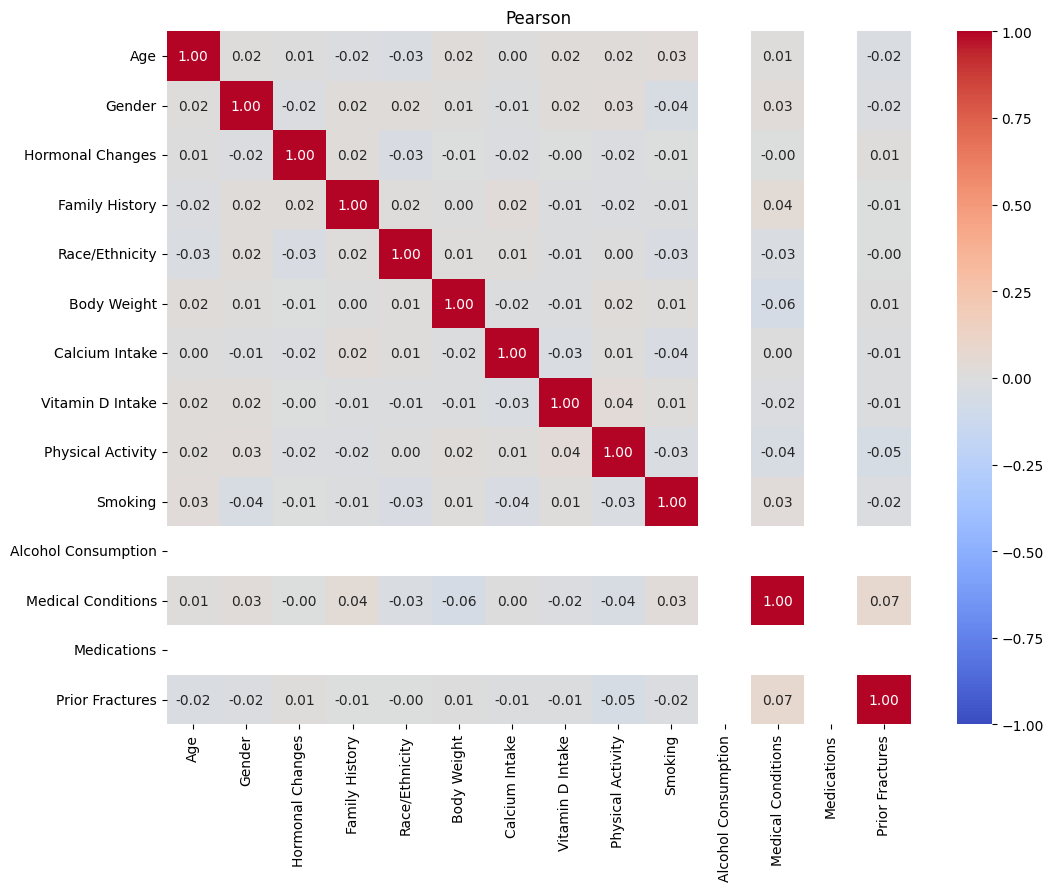

In [16]:
pearson = X.corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson")
plt.show()

## 9\.FAMD

FAMD \(Factor Analysis of Mixed Data\) merupakan metode reduksi dimensi yang dapat digunakan pada data campuran, yaitu data yang memiliki atribut numerik dan kategorikal sekaligus\. Pada dataset osteoporosis, hanya atribut Age yang bersifat numerik, sedangkan 13 atribut lainnya bersifat kategorikal\. Oleh karena itu, FAMD lebih tepat digunakan dibandingkan PCA, karena PCA hanya dirancang untuk data numerik

In [17]:
from sklearn.model_selection import train_test_split

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(1566, 14) (392, 14)
Osteoporosis
0    0.5
1    0.5
Name: proportion, dtype: float64
Osteoporosis
1    0.5
0    0.5
Name: proportion, dtype: float64


Data dibagi menjadi data latih \(80%\) sebanyak 1566 baris dan data uji \(20%\) sebanyak 392 baris\. Parameter stratify=y digunakan agar proporsi kelas target pada data latih dan data uji tetap sama, yaitu 50% untuk kelas 0 dan 50% untuk kelas 1\. Pembagian data dilakukan sebelum FAMD agar tidak terjadi data leakage, yaitu kondisi ketika informasi dari data uji ikut digunakan dalam proses pembelajaran\.

In [18]:
import prince

famd = prince.FAMD(n_components=10, random_state=42)
famd = famd.fit(X_train)                 

Z_train = famd.transform(X_train)        
Z_test  = famd.transform(X_test)  

Model FAMD dibentuk dengan 10 komponen\. Proses fit hanya dilakukan pada data latih \(X\_train\), sehingga dimensi yang terbentuk sepenuhnya dipelajari dari data latih\. Hasil FAMD tersebut kemudian digunakan untuk mentransformasi data latih \(Z\_train\) dan data uji \(Z\_test\)\. Dengan demikian, 14 atribut awal direduksi menjadi 10 dimensi baru\. Setiap dimensi merupakan kombinasi dari seluruh atribut asli\.

Atribut Age diubah ke tipe float agar dikenali sebagai atribut numerik, sedangkan atribut lain yang bertipe integer hasil label encoding dikenali sebagai atribut kategorikal\.

In [19]:
print(famd.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              1.162         8.94%                      8.94%
1              1.098         8.45%                     17.39%
2              1.089         8.37%                     25.76%
3              1.051         8.08%                     33.85%
4              1.037         7.98%                     41.82%
5              1.011         7.77%                     49.60%
6              1.009         7.76%                     57.36%
7              0.963         7.41%                     64.77%
8              0.948         7.29%                     72.06%
9              0.931         7.16%                     79.22%


Eigenvalue menunjukkan banyaknya informasi \(variansi\) yang dijelaskan oleh setiap dimensi\. Hasil menunjukkan bahwa eigenvalue setiap dimensi berada pada rentang 0,931–1,162, dengan proporsi variansi yang hampir merata, yaitu 7–9% per dimensi\. Dimensi pertama hanya menjelaskan 8,94% variansi, dan sepuluh dimensi pertama secara kumulatif menjelaskan 79,22% variansi data\.

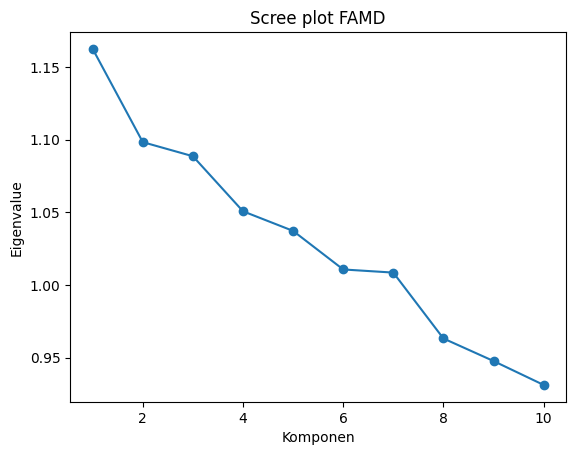

In [20]:
import matplotlib.pyplot as plt
import numpy as np

ev = famd.eigenvalues_
plt.plot(range(1, len(ev) + 1), ev, marker="o")
plt.xlabel("Komponen"); plt.ylabel("Eigenvalue"); plt.title("Scree plot FAMD")
plt.show()

Scree plot menunjukkan eigenvalue yang menurun secara perlahan dari 1,162 hingga 0,931 tanpa adanya titik siku \(elbow\) yang jelas\. Hal ini menegaskan bahwa tidak ada dimensi yang jauh lebih dominan dibanding dimensi lainnya\. Berdasarkan kriteria Kaiser \(eigenvalue \> 1\), terdapat 7 dimensi yang layak dipertahankan dengan total variansi 57,36%\. Pada penelitian ini digunakan 10 dimensi agar informasi yang dipertahankan lebih besar, yaitu 79,22%\.

In [21]:
kontribusi = famd.column_contributions_
print(kontribusi.round(3))

component                  0      1      2      3      4      5      6      7  \
variable                                                                        
Age                    0.006  0.281  0.027  0.002  0.078  0.005  0.058  0.000   
Gender_0               0.000  0.088  0.093  0.038  0.000  0.009  0.001  0.037   
Gender_1               0.000  0.087  0.091  0.038  0.000  0.008  0.001  0.036   
Hormonal Changes_0     0.012  0.000  0.034  0.036  0.052  0.093  0.120  0.004   
Hormonal Changes_1     0.012  0.000  0.033  0.035  0.051  0.091  0.118  0.004   
Family History_0       0.039  0.003  0.049  0.015  0.063  0.088  0.023  0.056   
Family History_1       0.041  0.003  0.052  0.016  0.067  0.094  0.025  0.060   
Race/Ethnicity_0       0.015  0.064  0.071  0.054  0.103  0.005  0.001  0.082   
Race/Ethnicity_1       0.006  0.032  0.017  0.197  0.069  0.119  0.007  0.045   
Race/Ethnicity_2       0.002  0.007  0.156  0.038  0.005  0.069  0.003  0.248   
Body Weight_0          0.032

Nilai kontribusi menunjukkan seberapa besar peran setiap kategori atribut dalam membentuk suatu dimensi\. Jumlah kontribusi dalam satu dimensi bernilai 1 \(100%\)\. Kontribusi per atribut diperoleh dengan menjumlahkan kontribusi seluruh kategorinya\.

Dimensi 1 paling banyak dibentuk oleh Medical Conditions \(27,9%\), Physical Activity \(26,9%\), dan Prior Fractures \(17,4%\)\. Dimensi ini dapat dimaknai sebagai faktor kondisi kesehatan dan aktivitas fisik\.
Dimensi 2 paling banyak dibentuk oleh Age \(28,1%\), Vitamin D Intake \(22,9%\), dan Gender \(17,5%\)\. Dimensi ini dapat dimaknai sebagai faktor demografi dan asupan nutrisi\.

Atribut Alcohol Consumption dan Medications memiliki kontribusi 0 pada seluruh dimensi\. Hal ini terjadi karena setelah imputasi menggunakan modus, kedua atribut tersebut hanya memiliki satu kategori \(zero variance\), sehingga tidak memberikan informasi apa pun dan dapat dihapus dari analisis\.

In [22]:
famd.plot(X_train, x_component=0, y_component=1)

alt.LayerChart(...)

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=03a5eb1b-4fa7-4299-b4b4-8fc0cc8fc75b' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>